In [ ]:
!pip install gymnasium

In [ ]:
!pip install "gymnasium[toy-text]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 48.2 MB/s eta 0:00:00


In [ ]:
import gymnasium as gym
import numpy as np
import random

# Q-learning


In [ ]:
gamma = 0.99
alpha = 0.5
episodes =500
epsilon = 0.1

In [ ]:
Q_values = np.zeros((48,4))

In [ ]:
def epsilon_greedy(state):
  if random.random()<epsilon:
    return env.action_space.sample()
  else:
    return np.argmax(Q_values[state])

In [ ]:
for episode in range(episodes):
  env=gym.make("CliffWalking-v1")
  done =False
  state,_= env.reset()
  # action = epsilon_greedy(state)
  total_reward = 0
  episode_len =0

  while not done:
    action = epsilon_greedy(state)
    next_state,reward,terminated,truncated,_= env.step(action)
    done = terminated or truncated
    # next_action = epsilon_greedy(next_state)
    Q_values[state,action] += alpha*(reward + gamma*np.max(Q_values[next_state]) - Q_values[state,action])

    state = next_state
    # action = next_action
    total_reward += reward
    episode_len+=1
  print(f"Episode {episode+1}/{episodes}: Total reward = {total_reward}  & ep length = {episode_len}")
  env.close()

Episode 0/500: Total reward = -117  & ep length = 117
Episode 1/500: Total reward = -1708  & ep length = 421
Episode 2/500: Total reward = -266  & ep length = 167
Episode 3/500: Total reward = -61  & ep length = 61
Episode 4/500: Total reward = -297  & ep length = 198
Episode 5/500: Total reward = -70  & ep length = 70
Episode 6/500: Total reward = -434  & ep length = 137
Episode 7/500: Total reward = -178  & ep length = 79
Episode 8/500: Total reward = -37  & ep length = 37
Episode 9/500: Total reward = -27  & ep length = 27
Episode 10/500: Total reward = -62  & ep length = 62
Episode 11/500: Total reward = -42  & ep length = 42
Episode 12/500: Total reward = -34  & ep length = 34
Episode 13/500: Total reward = -39  & ep length = 39
Episode 14/500: Total reward = -35  & ep length = 35
Episode 15/500: Total reward = -39  & ep length = 39
Episode 16/500: Total reward = -50  & ep length = 50
Episode 17/500: Total reward = -36  & ep length = 36
Episode 18/500: Total reward = -54  & ep len

In [ ]:
#what agent learn
env = gym.make("CliffWalking-v1", render_mode="rgb_array")
done =False
state,_= env.reset()

total_reward = 0
episode_len =0

while not done:
  action = np.argmax(Q_values[state])
  state,reward,terminated,truncated,_= env.step(action)
  done = terminated or truncated

  total_reward += reward
  episode_len+=1
print(f"Total reward = {total_reward}  & ep length = {episode_len}")
env.close()

Total reward = -13  & ep length = 13


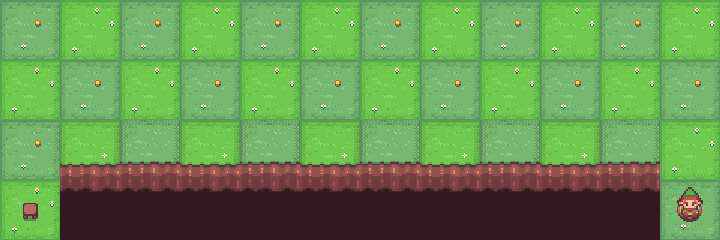

Total reward = -13 & ep length = 13


In [ ]:

from IPython.display import display, clear_output
from PIL import Image
import time

env = gym.make("CliffWalking-v1", render_mode="rgb_array")

done = False
state, _ = env.reset()

total_reward = 0
episode_len = 0

while not done:

    # Choose action
    action = np.argmax(Q_values[state])

    # Take action
    state, reward, terminated, truncated, _ = env.step(action)

    done = terminated or truncated

    total_reward += reward
    episode_len += 1

    # Get rendered frame
    frame = env.render()

    # Display frame
    clear_output(wait=True)
    display(Image.fromarray(frame))
    time.sleep(0.2)

print(f"Total reward = {total_reward} & ep length = {episode_len}")

env.close()